# LLM Hybrid: TF-IDF Retrieval + LLM Choice of Roud Song Clusters

Needs the docker container to be running.

1. TF-IDF word scores and cosine similarity rank every training song against the new song. The 5 most similar Roud numbers are candidates.
2. Qwen3-8B via llama.cpp reads the new lyrics and picks the one that is a version of the same song, or says "none".

In [ ]:
import json, time, hashlib, re
from pathlib import Path

import numpy as np
import pandas as pd
import requests

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, adjusted_rand_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

SEED = 1337

# LLM settings
SERVER = "http://127.0.0.1:8083"
MODEL = "qwen3-8b"
TOP_K = 5
SHOW_TITLES = False
THINKING = False
MAX_CHARS = 1800
CACHE = Path("llm_results.jsonl")

In [2]:
# Load the data, drop duplicates and any songs without lyrics
raw = pd.read_csv("dataset-v2.csv", dtype=str)

df_lyrics2 = pd.DataFrame({
    "name":    raw["title"],
    "roud":    raw["roud"],   # the answer we're evaluating
    "variant": raw["title"] + "# " + raw["version"],
    "lyrics":  raw["lyrics"],
})

df_lyrics2 = df_lyrics2.dropna(subset=["lyrics", "roud"])
df_lyrics2 = df_lyrics2.drop_duplicates(subset=["name", "lyrics", "roud"]).reset_index(drop=True)

print(len(df_lyrics2), "versions of", df_lyrics2.roud.nunique(), "songs")
df_lyrics2.head()

6828 versions of 2167 songs


,name,roud,variant,lyrics
0,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 1,"It being on the twenty-third of June-o,\nAs I ..."
1,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 2,As I was sitting with my glass and spoon\nOne ...
2,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 3,"It being on the third of June,\nas I sat weavi..."
3,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 4,As I was sitting with my jug and spoon\nOn one...
4,A Maid in Bedlam / Abroad As I Was Walking,578,A Maid in Bedlam / Abroad As I Was Walking# 1,Abroad as I was walking one evening in the spr...


In [3]:
# Keep ballads of three versions, so every fold below can train and test on each ballad
df_lyrics2["roud_count"] = df_lyrics2.groupby("roud")["roud"].transform("count")
df_roud_multiples = df_lyrics2[df_lyrics2["roud_count"] >= 3].reset_index(drop=True)
print(len(df_roud_multiples), "variants of", df_roud_multiples.roud.nunique(), "ballads kept")

5023 variants of 887 ballads kept


In [ ]:
Step 1: tf-idf

In [ ]:
# tf-idf settings
tfidf_params = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                    strip_accents="unicode", dtype=np.float32)

lyrics = df_roud_multiples["lyrics"].to_numpy()
titles = df_roud_multiples["name"].to_numpy()
roud = df_roud_multiples["roud"].to_numpy()
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(lyrics, roud))

df_pred = df_roud_multiples.copy()

In [5]:
# retrieval: for every test song, the TOP_K most similar distinct ballads among the training songs
candidates = [None] * len(lyrics)   # per song: list of {roud, train_idx, sim}, most similar first

for train_idx, test_idx in folds:
    vectorizer = TfidfVectorizer(**tfidf_params)
    X_train = vectorizer.fit_transform(lyrics[train_idx])
    X_test = vectorizer.transform(lyrics[test_idx])
    sims = (X_test @ X_train.T).toarray()       # rows are unit length, so dot product = cosine similarity

    for row, i in enumerate(test_idx):
        found, seen = [], set()
        for j in np.argsort(-sims[row]):
            r = roud[train_idx[j]]
            if r in seen:
                continue
            seen.add(r)
            found.append(dict(roud=r, train_idx=int(train_idx[j]), sim=float(sims[row, j])))
            if len(found) == TOP_K:
                break
        candidates[i] = found

df_pred["pred_top1"] = [c[0]["roud"] for c in candidates]
truth_rank = np.array([next((k + 1 for k, c in enumerate(cands) if c["roud"] == roud[i]), 0)
                       for i, cands in enumerate(candidates)])   # 0 = not in the candidates
df_pred["truth_rank"] = truth_rank

print(f"top-1 accuracy (retriever alone): {accuracy_score(roud, df_pred['pred_top1']):.3f}")
print(f"top-{TOP_K} recall (ceiling for the LLM): {(truth_rank > 0).mean():.3f}")
print("\nwhere the retriever ranked the true ballad:")
print(pd.Series(truth_rank).value_counts().sort_index().rename(index={0: "missing"}).to_string())

top-1 accuracy (retriever alone): 0.972
top-5 recall (ceiling for the LLM): 0.989

where the retriever ranked the true ballad:
missing      56
1          4880
2            68
3             8
4             8
5             3


## Step 2: the LLM decides

The prompt shows the new song and the 5 candidates labeled A to E. The model answers with a JSON object containing one letter,
or `"none"`. Three safeguards:

- **Roud numbers and (by default) titles are hidden.** The model has to match on the words of the song.
- **Candidates are shuffled** per song with a fixed seed, so "always pick A" doesn't reproduce the retriever.
- **The answer is grammar-constrained** by llama.cpp to the JSON schema, so it always parses (when thinking is off).

In [ ]:
LETTERS = "ABCDE"[:TOP_K]

SYSTEM = ("You are an expert on English and Scottish traditional folk song. Folk songs exist in many versions: the same song "
          "can have different titles, verses in a different order, missing or added verses, and changed names and places. "
          "Two texts are the same song when they share the same story, characters, situation and recurring lines, "
          "even if the wording differs. Two texts are different songs if they only share common phrases or a general theme.")

def clip(text):
    text = text.strip()
    if len(text) <= MAX_CHARS:
        return text
    return text[:MAX_CHARS].rsplit("\n", 1)[0] + "\n[...]"

def build_prompt(i, query_text, cands):
    rng = np.random.default_rng(SEED + i)
    shown = [cands[k] for k in rng.permutation(len(cands))]

    parts = ["Here is a newly collected folk song:\n\n# NEW SONG #n" + clip(query_text) + "\n\n"
             "Below are candidate songs from an index. Decide whether the new song is a version of one of them.\n"]
    for letter, c in zip(LETTERS, shown):
        header = f"# CANDIDATE {letter} #"
        if SHOW_TITLES:
            header += f"  (title: {titles[c['train_idx']]})"
        parts.append(header + "\n" + clip(lyrics[c["train_idx"]]) + "\n")
    parts.append("Which candidate is a version of the same song as the new song? "
                 f'Answer with JSON: {{"choice": "X"}} where X is one of {", ".join(LETTERS)}, '
                 'or "none" if the new song is not a version of any candidate.')
    return "\n".join(parts), shown

SCHEMA = {"type": "object",
          "properties": {"choice": {"type": "string", "enum": list(LETTERS) + ["none"]}},
          "required": ["choice"], "additionalProperties": False}

def ask_llm(prompt):
    body = {
        "model": MODEL,
        "messages": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
        "temperature": 0,
        "max_tokens": 700 if THINKING else 30,
        "chat_template_kwargs": {"enable_thinking": THINKING},
    }
    if not THINKING:   # a grammar would also constrain the thinking, so only use it when thinking is off
        body["response_format"] = {"type": "json_schema", "json_schema": {"name": "choice", "schema": SCHEMA}}
    r = requests.post(f"{SERVER}/v1/chat/completions", json=body, timeout=900)
    r.raise_for_status()
    out = r.json()
    text = out["choices"][0]["message"].get("content") or ""
    m = re.search(r'"choice"\s*:\s*"([A-Za-z]+)"', text)
    choice = m.group(1) if m else "parse_error"
    return choice, text, out.get("usage", {})

def server_ready():
    try:
        return requests.get(f"{SERVER}/health", timeout=3).status_code == 200
    except requests.RequestException:
        return False

while not server_ready():
    print(f"waiting for llama-server at {SERVER} ... start it with: sudo docker compose up -d", flush=True)
    time.sleep(30)
print("server model:", requests.get(f"{SERVER}/v1/models").json()["data"][0]["id"])

server model: qwen3-8b


In [ ]:
# quick test
i = 0
prompt, shown = build_prompt(i, lyrics[i], candidates[i])
print(prompt[:1500], "\n[...]\n")
t0 = time.time()
choice, text, usage = ask_llm(prompt)
print(f"answer: {text!r}  in {time.time() - t0:.1f} s, {usage.get('prompt_tokens')} prompt tokens")
print("true roud:", roud[i], " shuffled candidates:", [c["roud"] for c in shown],
      " -> chose:", shown[LETTERS.index(choice)]["roud"] if choice in LETTERS else choice)

Here is a newly collected folk song:

=== NEW SONG ===
It being on the twenty-third of June-o,
As I sat weaving all on my loom,
(repeat)
I heard a thrush singing on yon bush
And the song she sung was A Jug of Punch.

Chorus:
Ladderly fol the dee
Ladderly fol the dee deedle eedle dum
Ditbery idle dum ditbery idle deedle dum
Ditbery idle dum ditbery idle deedle dum
Ditbery idle deedle eedle dum dum dee.

What more pleasure could a boy desire
Than to sit him down-o, beside the fire,
(repeat)
And in his hand-o, a jug of punch,
Aye, and on his knee-o, a tidy wench.

What more hardships could a boy desire
Than sate him down-o, behind the door
(repeat)
Arid in his hand-o, no jug of punch
Aye, and on his knee-o, no tidy wench.

When I am dead, all my drinking’s over,
I’ll drink one glass and I’ll drink no more,
(repeat)
For fear I mightn’t get it on that day,
I will drink it now and I’ll drink away.

When I am dead and left in my mould
At my head and feet place a flowing bowl,
(repeat)
And eve

In [8]:
# run every song once. Answers are appended to the cache as they arrive, so this cell can be interrupted and re-run
def run_llm(indices, queries, cand_lists, tag):
    config = hashlib.md5(json.dumps(dict(model=MODEL, k=TOP_K, titles=SHOW_TITLES, thinking=THINKING,
                                         max_chars=MAX_CHARS, tag=tag), sort_keys=True).encode()).hexdigest()[:8]
    done = {}
    if CACHE.exists():
        for line in CACHE.open():
            rec = json.loads(line)
            if rec["config"] == config:
                done[rec["i"]] = rec
    todo = [i for i in indices if i not in done]
    print(f"[{tag}] {len(done)} cached, {len(todo)} to run")

    t_start = time.time()
    with CACHE.open("a") as f:
        for n, i in enumerate(todo, 1):
            prompt, shown = build_prompt(i, queries[i], cand_lists[i])
            t0 = time.time()
            choice, text, usage = ask_llm(prompt)
            rec = dict(i=int(i), config=config, choice=choice,
                       pred=shown[LETTERS.index(choice)]["roud"] if choice in LETTERS else "none",
                       order=[c["roud"] for c in shown], raw=text, secs=round(time.time() - t0, 2),
                       prompt_tokens=usage.get("prompt_tokens"), completion_tokens=usage.get("completion_tokens"))
            f.write(json.dumps(rec) + "\n")
            f.flush()
            done[i] = rec
            if n % 100 == 0 or n == len(todo):
                per = (time.time() - t_start) / n
                print(f"[{tag}] {n}/{len(todo)}  {per:.1f} s/song  ETA {(len(todo) - n) * per / 60:.0f} min", flush=True)
    return done

results = run_llm(range(len(lyrics)), lyrics, candidates, tag="closed-set")

df_pred["pred_llm"] = [results[i]["pred"] for i in range(len(lyrics))]
df_pred["llm_choice"] = [results[i]["choice"] for i in range(len(lyrics))]
df_pred["llm_secs"] = [results[i]["secs"] for i in range(len(lyrics))]
df_pred["prompt_tokens"] = [results[i]["prompt_tokens"] for i in range(len(lyrics))]
print(f"\n{(df_pred.pred_llm == 'none').sum()} songs answered 'none', "
      f"{(df_pred.llm_choice == 'parse_error').sum()} unparseable answers")
print(f"median {df_pred.llm_secs.median():.1f} s per song, median {df_pred.prompt_tokens.median():.0f} prompt tokens")

[closed-set] 5023 cached, 0 to run

105 songs answered 'none', 0 unparseable answers
median 1.3 s per song, median 2112 prompt tokens


## How good is it?

Same scoring as the classifier notebooks, so the rows are comparable. KNN and SVM are re-run here on the same folds.

- **Accuracy** = share of songs given the correct Roud number. A "none" answer counts as wrong.
- **Macro precision / recall / F1** average over ballads, so rare ballads count as much as common ones.
- **ARI** treats the predicted Roud numbers as clusters and compares them with the true ones. A "none" answer is a song left
  unplaced, so each gets its own singleton label, the same treatment the clustering notebooks give HDBSCAN noise.
- **Pure / mixed clusters, split ballads** as in the clustering notebooks, on the predicted labels.

In [9]:
# the KNN and SVM from tfidf_classifiers.ipynb, on these same folds, for a side-by-side table
knn = make_pipeline(TfidfVectorizer(**tfidf_params),
                    KNeighborsClassifier(n_neighbors=3, metric="cosine", weights="distance"))
df_pred["pred_knn"] = cross_val_predict(knn, lyrics, roud, cv=folds)

svm = make_pipeline(TfidfVectorizer(**tfidf_params), LinearSVC(random_state=SEED))
df_pred["pred_svm"] = cross_val_predict(svm, lyrics, roud, cv=folds)

In [10]:
def score_model(name, pred_col):
    pred = df_pred[pred_col].to_numpy()
    # For the cluster-style metrics, a "none" answer is a song left unplaced, not a cluster. As in the clustering
    # notebooks' handling of HDBSCAN noise, each one gets its own singleton label so they aren't scored as one big cluster
    lab = pred.astype(object).copy()
    none = lab == "none"
    lab[none] = [f"none_{k}" for k in range(none.sum())]
    tmp = pd.DataFrame({"roud": roud, "lab": lab})
    placed = tmp[~none]   # as in the clustering notebooks, unplaced songs don't count as clusters of their own
    per_cluster = placed.groupby("lab")["roud"].nunique()
    per_ballad  = placed.groupby("roud")["lab"].nunique()
    fold_acc = [accuracy_score(roud[test_idx], pred[test_idx]) for _, test_idx in folds]
    return {
        "model": name,
        "accuracy": accuracy_score(roud, pred),
        "accuracy_fold_std": np.std(fold_acc),
        "macro_f1": f1_score(roud, pred, average="macro", zero_division=0),
        "macro_precision": precision_score(roud, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(roud, pred, average="macro", zero_division=0),
        "ARI": adjusted_rand_score(roud, lab),
        "pure_clusters": (per_cluster == 1).sum(),
        "mixed_clusters": (per_cluster > 1).sum(),
        "split_ballads": (per_ballad > 1).sum(),
    }

df_results = pd.DataFrame([
    score_model("TF-IDF top-1 (retriever only)", "pred_top1"),
    score_model("TF-IDF top-5 + LLM", "pred_llm"),
    score_model("TF-IDF KNN (k=3)", "pred_knn"),
    score_model("TF-IDF SVM", "pred_svm"),
]).set_index("model").round(3)
df_results

,accuracy,accuracy_fold_std,macro_f1,macro_precision,macro_recall,ARI,pure_clusters,mixed_clusters,split_ballads
model,,,,,,,,,
TF-IDF top-1 (retriever only),0.972,0.004,0.969,0.974,0.969,0.946,775,111,115
TF-IDF top-5 + LLM,0.941,0.003,0.946,0.963,0.939,0.910,765,118,124
TF-IDF KNN (k=3),0.968,0.002,0.962,0.969,0.962,0.941,766,116,116
TF-IDF SVM,0.974,0.002,0.970,0.978,0.967,0.948,786,98,101


In [ ]:
# where did the LLM help, and where did it hurt?
top1_ok = df_pred.pred_top1 == df_pred.roud
llm_ok = df_pred.pred_llm == df_pred.roud
in_top5 = df_pred.truth_rank > 0

summary = pd.Series({
    "retriever right, LLM kept it":        (top1_ok & llm_ok).sum(),
    "retriever wrong, LLM fixed it":       (~top1_ok & llm_ok).sum(),
    "retriever right, LLM broke it":       (top1_ok & ~llm_ok).sum(),
    "both wrong":                          (~top1_ok & ~llm_ok).sum(),
    "  of which answer not in top 5":      (~in_top5).sum(),
    "  of which LLM said 'none'":          (~top1_ok & (df_pred.pred_llm == "none")).sum(),
})
print(summary.to_string())
print(f"\nLLM accuracy when the answer was among the candidates: {llm_ok[in_top5].mean():.3f}")
print(f"total LLM time: {df_pred.llm_secs.sum() / 3600:.2f} h  ({df_pred.llm_secs.mean():.1f} s/song)")

chosen_rank = []
for i, rec in results.items():
    if rec["choice"] in LETTERS:
        chosen_rank.append([c["roud"] for c in candidates[i]].index(rec["pred"]) + 1)
print("\nretriever rank of the candidate the LLM chose:")
print(pd.Series(chosen_rank).value_counts().sort_index().to_string())
print("\nletter chosen (should be roughly even if the shuffle removed position bias):")
print(df_pred.llm_choice.value_counts().to_string())

retriever right, LLM kept it      4693
retriever wrong, LLM fixed it       33
retriever right, LLM broke it      187
both wrong                         110
  of which answer not in top 5      56
  of which LLM said 'none'          40

LLM accuracy when the answer was among the candidates: 0.951
total LLM time: 1.90 h  (1.4 s/song)

retriever rank of the candidate the LLM chose:
1    4742
2     111
3      32
4      18
5      15

letter chosen (should be roughly even if the shuffle removed position bias):
llm_choice
C       1058
E       1040
D        995
B        970
A        855
none     105


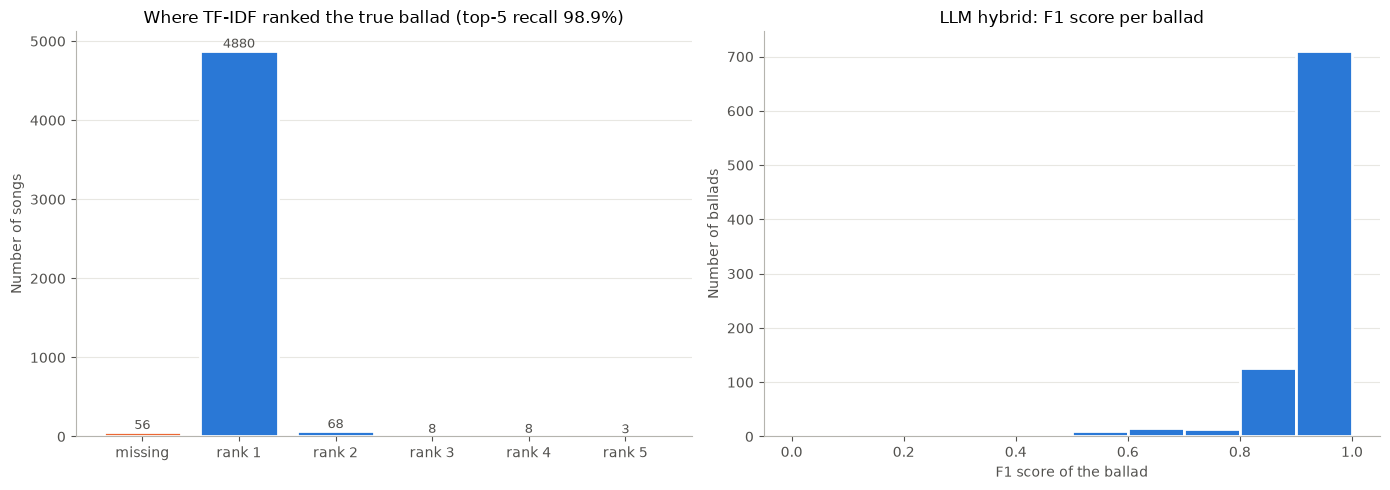

In [13]:
# chart: the retrieval ceiling, and how the LLM's mistakes split
fig, (ax_rank, ax_f1) = plt.subplots(1, 2, figsize=(14, 5))

rank_counts = pd.Series(truth_rank).value_counts().sort_index()
labels = ["missing" if r == 0 else f"rank {r}" for r in rank_counts.index]
colors = ["#eb6834" if r == 0 else "#2a78d6" for r in rank_counts.index]
bars = ax_rank.bar(labels, rank_counts.values, color=colors, edgecolor="white", linewidth=2)
ax_rank.bar_label(bars, color="#52514e", fontsize=9)
ax_rank.set_title(f"Where TF-IDF ranked the true ballad (top-{TOP_K} recall {(truth_rank > 0).mean():.1%})")
ax_rank.set_ylabel("Number of songs")
ax_rank.grid(axis="y", color="#e8e7e2")
ax_rank.set_axisbelow(True)

ballad_f1 = f1_score(roud, df_pred["pred_llm"], labels=np.unique(roud), average=None, zero_division=0)
ax_f1.hist(ballad_f1, bins=np.linspace(0, 1, 11), color="#2a78d6", edgecolor="white", linewidth=2)
ax_f1.set_title("LLM hybrid: F1 score per ballad")
ax_f1.set_xlabel("F1 score of the ballad")
ax_f1.set_ylabel("Number of ballads")
ax_f1.grid(axis="y", color="#e8e7e2")
ax_f1.set_axisbelow(True)

fig.tight_layout()
fig.savefig("ballad_predictions_llm.png", dpi=200)
plt.show()